# Designing a Topic Forest for Fast Retrieval of Past Questions
**HCI 2026 – Group 19 – Milestone 3**

In our prototype every prompt a student sends to the AI is sorted into a **knowledge forest**: **groups** (one per subject) hold **trees** of **topics**, and every prompt sits in one topic. After every prompt the system decides one of five outcomes:

| | outcome | meaning |
|---|---|---|
| (a) | add | the prompt goes into an existing topic |
| (b) | new branch | a new topic under an existing topic |
| (c) | new tree | a new topic directly under an existing group |
| (d) | new group | a new group (subject) with a new tree |
| (e) | restructure | older prompts move; a topic left empty is deleted |

```
new prompt + current forest -> [LLM judge] -> proposal and scores -> [integer program, Gurobi] -> new forest + outcome
```

The forest is there so that the student **finds earlier questions again**. Each step therefore minimizes the **time the student spends** (seconds): looking questions up, predicted by a user model of the tree view, plus the one-time cost of getting used to changes. Many small topics mean more levels to click through, few large ones mean long lists to read, and every restructure disturbs what the student has learned.

**Frozen LLM answers.** The LLM judge (Claude Haiku 5.5) was called once per question along the IP's path (Section 5a); its answers are saved in `llm_steps/` and replayed, so the notebook needs no key or login. To experiment, edit the questions in `session.py` or the parameters in Section 3 and re-run all cells (changed prompts are sent to the LLM again).

**Setup.** Run the notebook **locally** from its folder, next to `session.py`, `judge.py`, `forest.py`, `visualization.py` and `llm_steps/`, with the packages of `requirements.txt` (`README.md`, *How to run*). **Google Colab is optional:** there the next cell first downloads the repository and installs Gurobi. The free size-limited Gurobi license is enough (at most about 360 variables and 480 constraints per step, Section 5b).

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/UxAzhangxiaohua/hci_m3/blob/main/ui_optimization.ipynb)

In [23]:
import os, sys, subprocess

NEEDED = ["session.py", "judge.py", "forest.py", "visualization.py", "llm_steps"]   # must sit next to this notebook
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:   # optional: Colab starts in an empty folder, so download the repository and install Gurobi
    REPO, REF = "https://github.com/UxAzhangxiaohua/hci_m3.git", "main"    # REF: branch or tag to download
    if not all(os.path.exists(f) for f in NEEDED):
        if not os.path.exists("hci_m3"):
            subprocess.run(["git", "clone", "-q", "--depth", "1", "--branch", REF, REPO], check=True)
        os.chdir("hci_m3")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gurobipy"], check=True)

missing = [f for f in NEEDED if not os.path.exists(f)]
if missing:   # locally nothing is downloaded: the notebook uses the files next to it
    raise FileNotFoundError(f"{', '.join(missing)} not found in {os.getcwd()}. Start Jupyter in the folder "
                            "that contains this notebook and its helper files (README.md, How to run).")
print("running in", "Colab" if IN_COLAB else "a local Jupyter", f"(Python {sys.version.split()[0]})",
      "| working directory:", os.getcwd())

running in a local Jupyter (Python 3.12.11) | working directory: /Users/zhangshengyang/Downloads/ETH_study/sem7/HCI/hci_m3


In [24]:
# packages from requirements.txt (locally: pip install -r requirements.txt before starting Jupyter)
from itertools import combinations
import numpy as np
import pandas as pd
from gurobipy import Model, GRB, quicksum

import judge                                               # the LLM judge: prompt, answers (Section 2)
from session import SESSION, IDEAL                         # the scripted session (Section 1)
from forest import (ROOT, JUDGE, ALL_TOPICS, ALL_LABELS, SOURCE, initial_state, candidates_of, structure,
                    choice_points, apply, changes, action, code_of, describe, missing_scores, tree_of,
                    chronological, collect_llm_answers, export_sequence)       # bookkeeping of the forest
from visualization import (question_table, proposal_tables, step_table, outcome_table, show_session, show_step,
                           show_final_trees, animate_step, animate_session)    # figures and tables

pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 60)

# 1. The scripted study session
***
**Start.** The student has used the app before, while the forest was still coarse:

```
Deep learning (group)
├── Neural networks    ● p0  "What does an activation function do?"
│                      ● p1  "Why does a neural network need hidden layers?"
└── Gradient descent   ● p2  "What is gradient descent?"
                       ● p3  "How do I pick a good learning rate?"
                       ● p4  "Why does my loss explode when the learning rate is too high?"
                       ● p5  "What is the difference between a local and a global minimum?"
```

*Gradient descent* has grown long: four questions, two of them about the learning rate. When a fitting subtopic is proposed, should the old questions move into it? That is the restructure decision (e).

**Then eleven new questions arrive one by one** (`n1` … `n11`), chosen so that every outcome can occur: the learning-rate question that may split *Gradient descent* (n1); themes with two questions, where the first one may wait for the second (activation functions n2/n6, backpropagation n4/n5, optimizers n8/n9); a new subject (linear algebra: n3, n7, n10); and a theme that stays alone (dropout, n11). New topics are not written by us: the LLM **proposes** them (Section 2) and the solver decides at every step whether to create one; a proposal that is not created stays **open** for later steps.

The session is defined in `session.py`, including a hand-made ideal forest that is used only for evaluation (Section 7).

In [25]:
question_table()

,question
step,
1: n1,What does the learning rate do?
2: n2,Why is ReLU used instead of sigmoid?
3: n3,How do I find the eigenvalues of a 2x2 matrix?
4: n4,How does backpropagation compute the gradients?
5: n5,Chain rule through a 2-layer network
6: n6,What does the softmax function output?
7: n7,"If a matrix has an eigenvalue 0, is it still invertible?"
8: n8,How does Adam adapt the learning rate?
9: n9,What is momentum in SGD?


# 2. Proposals and semantic fit $s_{pc}$ from the LLM
***
The solver cannot judge meaning. **For every new question** one LLM prompt (`judge.step_prompt`, printed in the Appendix) does two tasks:

1. **Propose** at most one new topic, only if the question would fit it perfectly (5) and every listed topic at most 4: a name and a parent (a topic → new branch, a group → new tree, or a new group).
2. **Judge** the new question against every topic and open proposal, and every earlier question against the new proposal:

| score | meaning |
|---|---|
| 5 | the question is squarely about this topic |
| 4 | it belongs to a more specific subtopic of this topic that is not in the list |
| 3 | same broader area, different topic |
| 2 | loosely related |
| 1 | unrelated |

The LLM sees only the forest so far and the new question, in a fresh session; every score is asked once and never changes. We rescale it to the fit $s_{pc} = (j_{pc}-1)/4 \in \{0, 0.25, 0.5, 0.75, 1\}$. It enters the objective through the *misfiled* term (Section 4a): a question rated 4 or 5 for its topic is found there, unless another topic fits it better; the ratings of old questions against a new proposal decide whether they are misfiled once it exists.

In [26]:
def s(p, c):
    # fit of question p to topic c in [0, 1], from the LLM's score 1..5 (collected in Section 5a);
    # a pair that was never rated counts as 1 = unrelated
    return (int(JUDGE[p].get(c, 1)) - 1) / 4

def miss(p, c):
    # probability that the student does not look for p in c, when no other topic fits p better:
    # 0 for scores 5 and 4 (4 = "belongs to a subtopic that does not exist yet": c is still where they look),
    # 1 - s for lower scores
    return 0.0 if s(p, c) >= 0.75 else 1 - s(p, c)

# 3. Design parameters
***
All costs are in seconds of the student's time.

| Symbol | Value | Meaning and justification |
|---|---|---|
| $H$ | 10 | How often every question will be looked up again (e.g. when revising). Assumption; varied from 1 to 40 in Section 8. |
| $a$ | 1.1 s | Opening one level of the tree view: point and click (KLM pointing $P$ [Card, Moran & Newell 1980]). |
| $b$ | 0.15 s/bit | Choosing one of $n$ labelled options takes $b\log_2(n+1)$ (Hick–Hyman; ~150 ms/bit [Card, Moran & Newell 1983]). |
| $R$ | 1.0 s | Reading one question (about 8 words) while skimming a topic for a known one. |
| $\lambda,\ \lambda_G$ | 1.0 s | A new topic or group: its label is read once ($= R$). |
| $\mu_p$ | derived | A moved question costs one failed lookup in its old place (Section 4a). |
| $F$ | 5 s | Re-orientation after any restructure. Assumption; varied in Section 8. |
| `MAX_NEW` | 1 | Design rule: at most one new topic per step, so the forest grows slowly. |

In [27]:
PARAMS = dict(
    H=10,         # future lookups of every question (e.g. when revising for the exam)
    a=1.1,        # s, open one level of the tree view: point at a node and click (KLM)
    b=0.15,       # s/bit, Hick-Hyman: choosing one of n labelled options takes b*log2(n+1)
    R=1.0,        # s, read one question while scanning a topic
    lam=1.0,      # s, a new topic: its label is read once (= R)
    lam_G=1.0,    # s, a new group: its name is read once (= R)
    F=5.0,        # s, re-orientation after any restructure (a move or a deleted topic)
    MAX_NEW=1,    # design rule: at most one new topic per step
)

# 4. The user model and the integer program
***
## 4a. How long does it take to find an old question?
**Where the model comes from.** Cockburn, Gutwin & Greenberg (CHI 2007) predict the time to select an item from a menu as a *search/decision* time plus a *pointing* time (Fitts' law). The search time depends on how well the user knows the menu. A novice searches the items one after the other, which takes time **linear** in the number of items (visual search). An expert knows what to look for and only decides among the items, which follows the **Hick–Hyman law**, **logarithmic** in their number [Hick 1952; Hyman 1953]. With practice the model moves from the linear to the logarithmic form.

**What we take from it.** We use the same two parts for a lookup in our tree view:
- at every level the student chooses among **topic labels** they have seen before, short and meaningful, so we use the expert form, Hick–Hyman;
- inside a topic the **questions** are long texts without a short label, so the student scans them one by one: the novice form, linear;
- instead of a Fitts' law term, each level costs a constant $a$ for pointing and clicking (KLM pointing time), since the nodes of the tree view are of similar size and distance;
- the times of the levels add up along the path, as in a cascading menu.

Summed over all questions this is the **expected selection time** of the lecture's menu example, $T = \sum_i p_i t_i$ (every question looked up equally often), with $t_i$ from this model instead of pointing alone. We use it **twice**: as the **objective** of the integer program (4b), and to **evaluate** every design, the IP and the human-made rules (Section 7).

**The model.** One lookup of question $p$ in topic $c$: the student chooses the group, the tree and the branch at every level down to $c$, then reads the questions in $c$ one by one:

$$
T_p \;=\; \underbrace{\sum_{v\in A(c)}\big(a + b\log_2(n_v+1)\big)}_{\text{navigate: Hick–Hyman per level}}
\;+\; \underbrace{R\,\frac{|c|+1}{2}}_{\text{read the topic: linear scan}}
\;+\; \underbrace{u_p\,R\,\frac{N+1}{2}}_{\text{misfiled}},
\qquad u_p = \begin{cases}1 & \text{if a topic fits } p \text{ better than } c\\ m_{pc} & \text{otherwise}\end{cases},
\qquad m_{pc} = \begin{cases}0 & s_{pc} \ge 0.75 \text{ (score 4 or 5)}\\ 1-s_{pc} & \text{else}\end{cases}
$$

- **Navigate.** $A(c)$: the choice points above $c$ (the forest, the group, every topic above $c$), each offering $n_v$ options.
- **Read the topic.** The student scans the $|c|$ questions until the right one: $(|c|+1)/2$ on average (serial self-terminating search).
- **Misfiled.** The student looks where $p$ fits best; if $p$ is not there, they scan the whole history of $N$ questions. A score of 4 means that $p$ belongs to a more specific subtopic that does not exist yet, so its topic is still where the student looks: $m_{pc} = 0$.

This is the **breadth vs. depth** trade-off of menus [Miller 1981; Kiger 1984]: more topics cost more levels and options (logarithmic), fewer topics cost longer lists (linear). Changes cost once: a new label is read ($\lambda$, $\lambda_G$), a moved question is first looked for in its old place ($\mu_p$: navigate there and read all of $c^0(p)$), and a restructure needs a look over the changed tree ($F$).

In [28]:
def hick(n, params=PARAMS):
    # time to choose one of n labelled options (Hick-Hyman law), in s
    return params["b"] * np.log2(n + 1)

def retrieval_times(state, params=PARAMS, informative=True):
    # one lookup of every question in the forest `state`: {question: {"navigate", "read", "misfiled"}} in s.
    # informative=False: the topic labels say nothing about the content (H0), so every lookup ends in the history.
    topics, assign = state["topics"], state["assign"]
    parent = {c: t["parent"] for c, t in topics.items()}
    options = {ROOT: len(state["groups"]), **{v: sum(parent[c] == v for c in topics) for v in [*state["groups"], *topics]}}
    size = {c: sum(t == c for t in assign.values()) for c in topics}
    N, R = len(assign), params["R"]
    T = {}
    for p, c in assign.items():
        if informative:   # p is misfiled if a topic fits it better (the student looks there first), else miss(p, c)
            u = max([miss(p, c)] + [1.0 for k in topics if s(p, k) > s(p, c)])
        else:
            u = 1.0
        T[p] = dict(navigate=sum(params["a"] + hick(options[v], params) for v in choice_points(parent, c)),
                    read=R * (size[c] + 1) / 2,
                    misfiled=u * R * (N + 1) / 2)
    return T

def lookup_time(state, params=PARAMS, informative=True):
    # mean time of one lookup of a question in this forest, in s
    T = retrieval_times(state, params, informative)
    return sum(sum(t.values()) for t in T.values()) / len(T)

TIE = 1e-3   # s per question asked later: among equally good moves, move the most recent question

def move_costs(state, params=PARAMS):
    # moving old question p costs one failed lookup: the next time, the student looks for p where it was
    # (navigate to its old topic and read all of it) before finding it in its new place. Plus a tie-breaker
    # far below any real difference: two questions with the same scores cost the same to move, so the more
    # recent one moves (its place is the least familiar), instead of an arbitrary choice of the solver.
    T = retrieval_times(state, params)
    size = {c: sum(t == c for t in state["assign"].values()) for c in state["topics"]}
    order = list(state["assign"])                        # in the order the questions were asked
    return {p: T[p]["navigate"] + params["R"] * size[c] + TIE * (len(order) - 1 - i)
            for i, (p, c) in enumerate(state["assign"].items())}

## 4b. The integer program for one step
At a step, the forest before the step is fixed input:

- $G^{old}$ / $G^{new}$: existing groups / groups an open proposal would create
- $C^{old}$ / $C^{new}$: existing topics / **open proposals** (proposed for this or an earlier question, not created yet); $C = C^{old}\cup C^{new}$
- $\pi(c)$: parent of topic $c$ (a topic or a group); $K(c)$: its subtopics
- $V$: the choice points (root $r$, every group, every topic that can have subtopics); $O(v)$: the options $v$ can offer; $B(v)$: the topics below $v$
- $P^{old}$: prompts in the forest, each in topic $c^0(p)$; $n$: the new prompt; $P = P^{old}\cup\{n\}$, $N=|P|$

### Decision variables
| Variable | Meaning |
|---|---|
| $q_{pc}\in\{0,1\}$ | prompt $p$ is in topic $c$ after this step |
| $y_c\in\{0,1\}$ | topic $c$ exists after this step (old topic: kept or deleted; proposal: created) |
| $g_G\in\{0,1\}$ | new group $G$ is created |
| $z\in\{0,1\}$ | the step is a restructure (an old prompt moves) |
| $e_{vk}\in\{0,1\}$, $\omega_{vk}\ge 0$ | choice point $v$ offers $k$ options; the prompts passing through $v$ if so, else 0 |
| $\delta_{ck}\in[0,1]$, $k=1..N$ | the $k$-th prompt of topic $c$ (filled from $k=1$ upwards) |
| $u_p\in[0,1]$ | prompt $p$ is misfiled |

### Constraints
$$
\begin{aligned}
&\textstyle\sum_{c\in C} q_{pc} = 1 && \forall p\in P && \text{(1) each prompt in exactly one topic}\\
&q_{pc} \le y_c && \forall p\in P,\ c\in C && \text{(2) only into topics that exist}\\
&\textstyle y_c \le \sum_{p} q_{pc} + \sum_{k\in K(c)} y_k && \forall c\in C && \text{(3) no empty topics (an emptied old topic is deleted)}\\
&y_c \le y_{\pi(c)} && \forall c\in C,\ \pi(c)\in C && \text{(4) a branch needs its parent topic}\\
&y_c \le g_{\pi(c)} && \forall c\in C,\ \pi(c)\in G^{new} && \text{(5) a tree in a new group needs the group}\\
&\textstyle\sum_k e_{vk} = 1,\quad \sum_k k\,e_{vk} = n_v && \forall v\in V && \text{(6) count the options: } n_r = |G^{old}|+\textstyle\sum_G g_G,\ n_v=\sum_{c\in O(v)} y_c\\
&\textstyle\omega_{vk} \ge \sum_{p}\sum_{c\in B(v)} q_{pc} - N(1-e_{vk}) && \forall v\in V\setminus\{r\},\ k && \text{(7) prompts that pass through } v\\
&\textstyle\sum_p q_{pc} = \sum_{k=1}^{N} \delta_{ck} && \forall c\in C && \text{(8) the size of a topic}\\
&\textstyle u_p \ge \sum_c m_{pc}\,q_{pc},\quad u_p \ge y_k - \sum_{c:\,s_{pc}\ge s_{pk}} q_{pc} && \forall p\in P,\ k\in C && \text{(9) misfiled: a poor fit, or a better topic exists}\\
&\textstyle \sum_{c\ne c^0(p):\,s_{pc}<s_{pk}} q_{pc} + y_k \le 1 && \forall p\in P,\ k\in C && \text{(10) file by meaning: place or move only into a best-fitting topic}\\
&z \ge 1 - q_{p,c^0(p)} && \forall p\in P^{old} && \text{(11) a move is a restructure}\\
&\textstyle\sum_{c\in C^{new}} y_c \le \texttt{MAX\_NEW} && && \text{(12) slow growth}
\end{aligned}
$$

**Linearization.** The navigation time is a product: the choice time $\log_2(n_v+1)$, which is not linear in the number of options, times the number of prompts that pass through $v$. (6) selects the count with $e_{vk}$, its time comes from a table, and the big-M constraint (7) gives $\omega_{vk}$ the number of prompts when the count is $k$ (0 otherwise, since we minimize). The reading time of a topic, $R\,|c|(|c|+1)/2$, is convex in its size: the $k$-th prompt adds $R\,k$. (8) splits the size into increments $\delta_{ck}$ that cost $R\,k$; since the cost grows with $k$, the minimum fills them from $k = 1$ upwards, so the sum is exact without binaries. The result is a mixed-integer *linear* program.

**Misfiling (9), (10).** The student looks for a question in the topic that fits it best, so it is misfiled if a better-fitting topic exists, otherwise with probability $m_{pc}$ (Section 4a). (10) is a design rule: the system never places or moves a prompt into a topic that fits worse than another existing one. Old prompts can still become misfiled passively, when a better topic is created and they are not moved: this is the restructure trade-off.

**What we left out.** A deleted topic needs no constraint of its own: it is deleted only when its prompts move, which already sets $z$ by (11). A new group without a tree is never chosen, because it only costs. (12) is a design rule rather than part of the user model: it never binds in the default run, but in some what-if runs a restructure would otherwise create two topics at once.

### Objective (minimize, seconds)
$$
\min\;
H\Big[\underbrace{N\sum_k \big(a+b\log_2(k+1)\big)e_{rk} + \sum_{v\ne r}\sum_k \big(a+b\log_2(k+1)\big)\,\omega_{vk}}_{\text{navigate}}
+\underbrace{\sum_{c\in C}\sum_{k=1}^{N} R\,k\,\delta_{ck}}_{\text{read the topic}}
+\underbrace{R\,\frac{N+1}{2}\sum_{p} u_p}_{\text{misfiled}}\Big]
+\underbrace{\lambda\sum_{c\in C^{new}} y_c+\lambda_G\sum_{G} g_G}_{\text{new labels}}
+\underbrace{\sum_{p\in P^{old}} \mu_p\,\big(1-q_{p,c^0(p)}\big) + F\,z}_{\text{disruption}}
$$

The bracket is $\sum_p T_p$ (Section 4a): one lookup of every question, counted $H$ times. **The outcome** follows from the new prompt's topic $c^*$: old → (a); new under a topic → (b); new under an old group → (c); new under a new group → (d); $z=1$ → (e).

**Not a simple rule.** Putting every prompt into its best-fitting topic (rule H2, Section 7) ignores the old prompts and the length of topics. Here the reading term rewards splitting a long topic, even by moving old prompts, while navigation, new labels and disruption penalize it.

In [29]:
def solve_step(state, step, params=PARAMS, verbose=False, exclude=None):
    # exclude: an assignment {prompt: topic} that the solution must differ from (to find the second best)
    n = step["id"]
    C_old, C_new, parent, kids, G_new = structure(state, step)
    C = C_old + C_new
    P_old = list(state["assign"])
    P = P_old + [n]
    c0, N = state["assign"], len(P)
    # choice points and the options they may offer: the forest (groups), every group (its trees), every topic
    # (its subtopics); a topic without possible subtopics is no choice point
    opts = {ROOT: list(state["groups"]) + G_new}
    for v in list(state["groups"]) + G_new + C:
        if any(parent[c] == v for c in C):
            opts[v] = [c for c in C if parent[c] == v]

    # ==== 1. Create the (empty) model ====
    model = Model(f"step_{n}")
    model.Params.OutputFlag = 1 if verbose else 0
    model.Params.MIPGap = 0            # prove optimality exactly (the default stops within 0.01 %)
    model.Params.IntFeasTol = 1e-9     # binaries exactly 0 or 1, so the big-M constraint (7) is exact

    # ==== 2. Add decision variables ====
    q = {(p, c): model.addVar(vtype=GRB.BINARY, name=f"q[{p},{c}]") for p in P for c in C}
    y = {c: model.addVar(vtype=GRB.BINARY, name=f"y[{c}]") for c in C}
    g = {G: model.addVar(vtype=GRB.BINARY, name=f"g[{G}]") for G in G_new}
    z = model.addVar(vtype=GRB.BINARY, name="z")
    e = {(v, k): model.addVar(vtype=GRB.BINARY, name=f"e[{v},{k}]") for v in opts for k in range(len(opts[v]) + 1)}
    om = {(v, k): model.addVar(lb=0, name=f"omega[{v},{k}]") for v in opts if v != ROOT for k in range(len(opts[v]) + 1)}
    d = {(c, k): model.addVar(lb=0, ub=1, name=f"delta[{c},{k}]") for c in C for k in range(1, N + 1)}
    u = {p: model.addVar(lb=0, ub=1, name=f"u[{p}]") for p in P}

    # ==== 3. Add constraints ====
    size = {c: quicksum(q[p, c] for p in P) for c in C}
    for p in P:                                                                        # (1)
        model.addConstr(quicksum(q[p, c] for c in C) == 1, name=f"one_topic[{p}]")
    for c in C:
        for p in P:                                                                    # (2)
            model.addConstr(q[p, c] <= y[c], name=f"exists[{p},{c}]")
        model.addConstr(y[c] <= size[c] + quicksum(y[k] for k in kids[c]), name=f"not_empty[{c}]")   # (3)
        if parent[c] in y:                                                             # (4)
            model.addConstr(y[c] <= y[parent[c]], name=f"parent[{c}]")
        if parent[c] in g:                                                             # (5)
            model.addConstr(y[c] <= g[parent[c]], name=f"group[{c}]")
    options = {ROOT: len(state["groups"]) + quicksum(g.values()),
               **{v: quicksum(y[c] for c in opts[v]) for v in opts if v != ROOT}}
    below = {v: quicksum(q[p, c] for p in P for c in C if v in choice_points(parent, c)) for v in opts if v != ROOT}
    for v in opts:
        ks = range(len(opts[v]) + 1)
        model.addConstr(quicksum(e[v, k] for k in ks) == 1, name=f"one_count[{v}]")                # (6)
        model.addConstr(quicksum(k * e[v, k] for k in ks) == options[v], name=f"count[{v}]")       # (6)
        if v != ROOT:
            for k in ks:                                                                           # (7)
                model.addConstr(om[v, k] >= below[v] - N * (1 - e[v, k]), name=f"below[{v},{k}]")
    for c in C:                                                                        # (8)
        model.addConstr(size[c] == quicksum(d[c, k] for k in range(1, N + 1)), name=f"size[{c}]")
    for p in P:                                                                        # (9)
        model.addConstr(u[p] >= quicksum(miss(p, c) * q[p, c] for c in C), name=f"fit[{p}]")
        for k in C:   # topic k exists and fits p better than p's own topic: p is misfiled
            model.addConstr(u[p] >= y[k] - quicksum(q[p, c] for c in C if s(p, c) >= s(p, k)), name=f"better[{p},{k}]")
    for p in P:                                                                        # (10)
        for k in C:   # p is only placed (new) or moved into a topic that fits it best among those that exist
            worse = [c for c in C if s(p, c) < s(p, k) and c != c0.get(p)]
            if worse:
                model.addConstr(quicksum(q[p, c] for c in worse) + y[k] <= 1, name=f"by_meaning[{p},{k}]")
    for p in P_old:                                                                    # (11)
        model.addConstr(z >= 1 - q[p, c0[p]], name=f"restructure[{p}]")
    model.addConstr(quicksum(y[c] for c in C_new) <= params["MAX_NEW"], name="max_new")   # (12)
    if exclude is not None:   # no-good cut: at least one prompt is placed differently than in `exclude`
        model.addConstr(quicksum(q[p, exclude[p]] for p in P) <= len(P) - 1, name="exclude")

    # ==== 4. Specify objective function (seconds) ====
    a, R = params["a"], params["R"]
    navigate = N * quicksum((a + hick(k, params)) * e[ROOT, k] for k in range(len(opts[ROOT]) + 1)) \
             + quicksum((a + hick(k, params)) * om[v, k] for v, k in om)
    read = R * quicksum(k * d[c, k] for c, k in d)          # = R * |c|(|c|+1)/2 per topic
    misfiled = R * (N + 1) / 2 * quicksum(u.values())
    growth = params["lam"] * quicksum(y[c] for c in C_new) + params["lam_G"] * quicksum(g.values())
    mu = move_costs(state, params)
    disruption = quicksum(mu[p] * (1 - q[p, c0[p]]) for p in P_old) + params["F"] * z
    model.setObjective(params["H"] * (navigate + read + misfiled) + growth + disruption, GRB.MINIMIZE)

    # ==== 5. Optimize model ====
    model.optimize()
    if exclude is not None and model.Status == GRB.INFEASIBLE:
        return None, None
    assert model.Status == GRB.OPTIMAL, f"Gurobi status {model.Status}"

    # ==== 6. Extract solution: where every prompt is after this step ====
    new_assign = {p: next(c for c in C if q[p, c].X > 0.5) for p in P}
    SIZES[n] = dict(variables=model.NumVars, constraints=model.NumConstrs)
    return new_assign, model.ObjVal

SIZES = {}   # model size per step (the pip license allows 2000 variables and 2000 constraints)

`evaluate_step` scores **any** decision with the same objective, so that the optimum can be compared with human-made rules; on the solver's decision it must equal Gurobi's objective value (a check of the implementation). The bookkeeping (`apply`: the forest after a decision, `changes`, `action`: the outcome (a)–(e)) is in `forest.py`.

In [30]:
def evaluate_step(state, step, new_assign, params=PARAMS, informative=True):
    # the IP's objective for any decision, split into its parts (s)
    after = apply(state, step, new_assign)
    moved, created, deleted, new_groups = changes(state, after)
    T, mu = retrieval_times(after, params, informative), move_costs(state, params)
    parts = {k: params["H"] * sum(T[p][k] for p in T) for k in ("navigate", "read", "misfiled")}
    parts["new topics/groups"] = params["lam"] * len(created) + params["lam_G"] * len(new_groups)
    parts["disruption"] = sum(mu[p] for p in moved) + params["F"] * bool(moved or deleted)
    parts["cost"] = sum(parts.values())
    return parts

# 5. Run the session step by step
***
`run_session` starts from the initial forest and, for every new prompt, asks a decision rule (here the IP) where everything goes, records the outcome and applies it.

In [31]:
def ip_policy(state, step, params):
    return solve_step(state, step, params)[0]

def run_session(policy=ip_policy, params=PARAMS):
    state, history = initial_state(), []
    for k, step in enumerate(SESSION, start=1):
        new_assign = policy(state, step, params)
        history.append(dict(k=k, step=step, before=state, after=apply(state, step, new_assign),
                            action=action(state, step, new_assign), missing=missing_scores(state, step),
                            parts=evaluate_step(state, step, new_assign, params), params=params))
        state = history[-1]["after"]
    return history

## 5a. Ask the LLM step by step
***
`collect_llm_answers` (in `forest.py`) walks through the session like the prototype: at step $k$ it builds the prompt from the forest after step $k-1$ and the $k$-th question, gets Claude Haiku 5.5's answer, lets the IP decide the step and continues.

**Simulation.** The answers were collected once (27 Nov 2026) and are saved in `llm_steps/` (prompt, answer and model per step). Every run rebuilds each prompt and checks that it equals the saved one, so the replay follows exactly the path on which the answers were given. If the questions or the parameters change, the notebook stops; after deleting the affected answers, `judge.answer` asks Haiku again.

In [32]:
collect_llm_answers(decide=lambda state, step: solve_step(state, step)[0])    # the IP decides every step
print("Using:", SOURCE)
print("Answered by:", {n: f'{a["model"]} ({a["via"]})' for n, a in judge.answered_by().items()})

Using: LLM, step by step (Claude Haiku 5.5 (claude-haiku-5-5), one fresh conversation per question that sees only that step's prompt); answers in llm_steps/
Answered by: {'n1': 'claude-haiku-5-5 (claude-cli)', 'n2': 'claude-haiku-5-5 (claude-cli)', 'n3': 'claude-haiku-5-5 (claude-cli)', 'n4': 'claude-haiku-5-5 (claude-cli)', 'n5': 'claude-haiku-5-5 (claude-cli)', 'n6': 'claude-haiku-5-5 (claude-cli)', 'n7': 'claude-haiku-5-5 (claude-cli)', 'n8': 'claude-haiku-5-5 (claude-cli)', 'n9': 'claude-haiku-5-5 (claude-cli)', 'n10': 'claude-haiku-5-5 (claude-cli)', 'n11': 'claude-haiku-5-5 (claude-cli)'}


The proposals and the fits $s_{pc}$: the best topic before each step (no proposal when it already fits perfectly), the fits **when a question arrived** ("-": topic proposed later), and the later ratings of earlier questions against new proposals, which decide whether to **move** them (e).

In [33]:
proposal_tables(s)

,question,best topic before this step,proposed topic,where
step,,,,
1: n1,What does the learning rate do?,Gradient descent (4),Learning rate,branch of Gradient descent
2: n2,Why is ReLU used instead of sigmoid?,Neural networks (4),Activation functions,branch of Neural networks
3: n3,How do I find the eigenvalues of a 2x2 matrix?,Neural networks (2),Eigenvalues,new tree in Linear algebra (new group)
4: n4,How does backpropagation compute the gradients?,Neural networks (4),Backpropagation,branch of Neural networks
5: n5,Chain rule through a 2-layer network,Backpropagation (5),-,
6: n6,What does the softmax function output?,Activation functions (5),-,
7: n7,"If a matrix has an eigenvalue 0, is it still invertible?",Eigenvalues (5),-,
8: n8,How does Adam adapt the learning rate?,Gradient descent (4),Optimizers,branch of Gradient descent
9: n9,What is momentum in SGD?,Optimizers (5),-,


Fit s_pc when the question arrived ('-' = topic proposed later)


,Neural networks,Gradient descent,Learning rate,Activation functions,Eigenvalues,Backpropagation,Optimizers,Singular value decomposition,Regularization
p0,1.00,0.50,-,-,-,-,-,-,-
p1,1.00,0.50,-,-,-,-,-,-,-
p2,0.50,1.00,-,-,-,-,-,-,-
p3,0.50,0.75,-,-,-,-,-,-,-
p4,0.50,0.75,-,-,-,-,-,-,-
p5,0.50,1.00,-,-,-,-,-,-,-
n1,0.50,0.75,1.00,-,-,-,-,-,-
n2,0.75,0.25,0.00,1.00,-,-,-,-,-
n3,0.25,0.25,0.00,0.00,1.00,-,-,-,-
n4,0.75,0.50,0.25,0.25,0.00,1.00,-,-,-


Ratings of earlier questions against later proposals (for moving them), with the step they were asked


,Learning rate,Activation functions,Eigenvalues,Backpropagation,Optimizers,Singular value decomposition,Regularization
p0,0.00 (step 1),1.00 (step 2),0.00 (step 3),0.25 (step 4),0.00 (step 8),0.00 (step 10),0.00 (step 11)
p1,0.00 (step 1),0.25 (step 2),0.00 (step 3),0.25 (step 4),0.00 (step 8),0.00 (step 10),0.00 (step 11)
p2,0.25 (step 1),0.25 (step 2),0.25 (step 3),0.50 (step 4),0.50 (step 8),0.00 (step 10),0.00 (step 11)
p3,1.00 (step 1),0.00 (step 2),0.00 (step 3),0.25 (step 4),0.50 (step 8),0.00 (step 10),0.00 (step 11)
p4,1.00 (step 1),0.00 (step 2),0.00 (step 3),0.25 (step 4),0.25 (step 8),0.00 (step 10),0.00 (step 11)
p5,0.25 (step 1),0.00 (step 2),0.00 (step 3),0.25 (step 4),0.25 (step 8),0.00 (step 10),0.25 (step 11)
n1,,0.00 (step 2),0.00 (step 3),0.25 (step 4),0.25 (step 8),0.00 (step 10),0.00 (step 11)
n2,,,0.00 (step 3),0.25 (step 4),0.00 (step 8),0.00 (step 10),0.00 (step 11)
n3,,,,0.00 (step 4),0.00 (step 8),0.50 (step 10),0.00 (step 11)
n4,,,,,0.25 (step 8),0.00 (step 10),0.00 (step 11)


## 5b. The IP's decisions

In [34]:
ip_history = run_session()

# checks: in every step our evaluation equals Gurobi's objective value, and no score was missing
for h in ip_history:
    obj = solve_step(h["before"], h["step"])[1]
    assert abs(obj - h["parts"]["cost"]) < 1e-6, (h["k"], obj, h["parts"])
    assert h["missing"] == 0, (h["k"], h["missing"])
print("check passed: Gurobi objective == evaluate_step and no missing scores in all", len(ip_history), "steps")
print("largest model:", max(v["variables"] for v in SIZES.values()), "variables,",
      max(v["constraints"] for v in SIZES.values()), "constraints (pip license: 2000 each)\n")

step_table(ip_history, s, lookup_time)

check passed: Gurobi objective == evaluate_step and no missing scores in all 11 steps
largest model: 362 variables, 483 constraints (pip license: 2000 each)



,new question,placed in,fit (judge score),created,moved / deleted,outcome,lookup time (s)
step,,,,,,,
1,What does the learning rate do?,Learning rate,1.00 (5),Learning rate,"p3 → Learning rate, p4 → Learning rate","(e) restructure: move p3, p4 + new branch",4.838
2,Why is ReLU used instead of sigmoid?,Activation functions,1.00 (5),Activation functions,-,(b) new branch,4.838
3,How do I find the eigenvalues of a 2x2 matrix?,Eigenvalues,1.00 (5),"Eigenvalues, group Linear algebra",-,(d) new group,4.777
4,How does backpropagation compute the gradients?,Backpropagation,1.00 (5),Backpropagation,-,(b) new branch,4.809
5,Chain rule through a 2-layer network,Backpropagation,1.00 (5),-,-,(a) add to existing topic,4.919
6,What does the softmax function output?,Activation functions,1.00 (5),-,-,(a) add to existing topic,5.010
7,"If a matrix has an eigenvalue 0, is it still invertible?",Eigenvalues,1.00 (5),-,-,(a) add to existing topic,4.977
8,How does Adam adapt the learning rate?,Optimizers,1.00 (5),Optimizers,-,(b) new branch,4.999
9,What is momentum in SGD?,Optimizers,1.00 (5),-,-,(a) add to existing topic,5.066


Gurobi's result for the first restructure (e) of the session (pass `verbose=True` to `solve_step` for the full solver log):

In [35]:
K_SHOW = next((h["k"] for h in ip_history if code_of(h["action"]) == "e"), len(ip_history))
h = ip_history[K_SHOW - 1]
print(f'step {K_SHOW}: {h["action"]}')
print(f'{SIZES[h["step"]["id"]]["variables"]} variables, {SIZES[h["step"]["id"]]["constraints"]} constraints; '
      f'optimal cost {h["parts"]["cost"]:.1f} s, proven with MIPGap 0')
pd.Series(h["parts"], name="cost (s)")

step 1: (e) restructure: move p3, p4 + new branch
65 variables, 95 constraints; optimal cost 357.8 s, proven with MIPGap 0


navigate             218.642
read                 120.000
misfiled               0.000
new topics/groups      1.000
disruption            18.178
cost                 357.821
Name: cost (s), dtype: float64

# 6. Showing the session as a growing knowledge forest
***
Each forest is drawn like the prototype's **tree view**: groups on the ground, topics branching upwards, dots are prompts. **Blue** = the prompt of this step, **orange** = an old prompt moved in this step (dashed arrow from where), gray = unchanged; a **dashed orange box** marks a topic or group created in this step. The figures and tables are in `visualization.py`.

## Visualization: the whole session with the IP
Read the panels left to right, top to bottom. Each panel is the forest the user sees **after** that step.

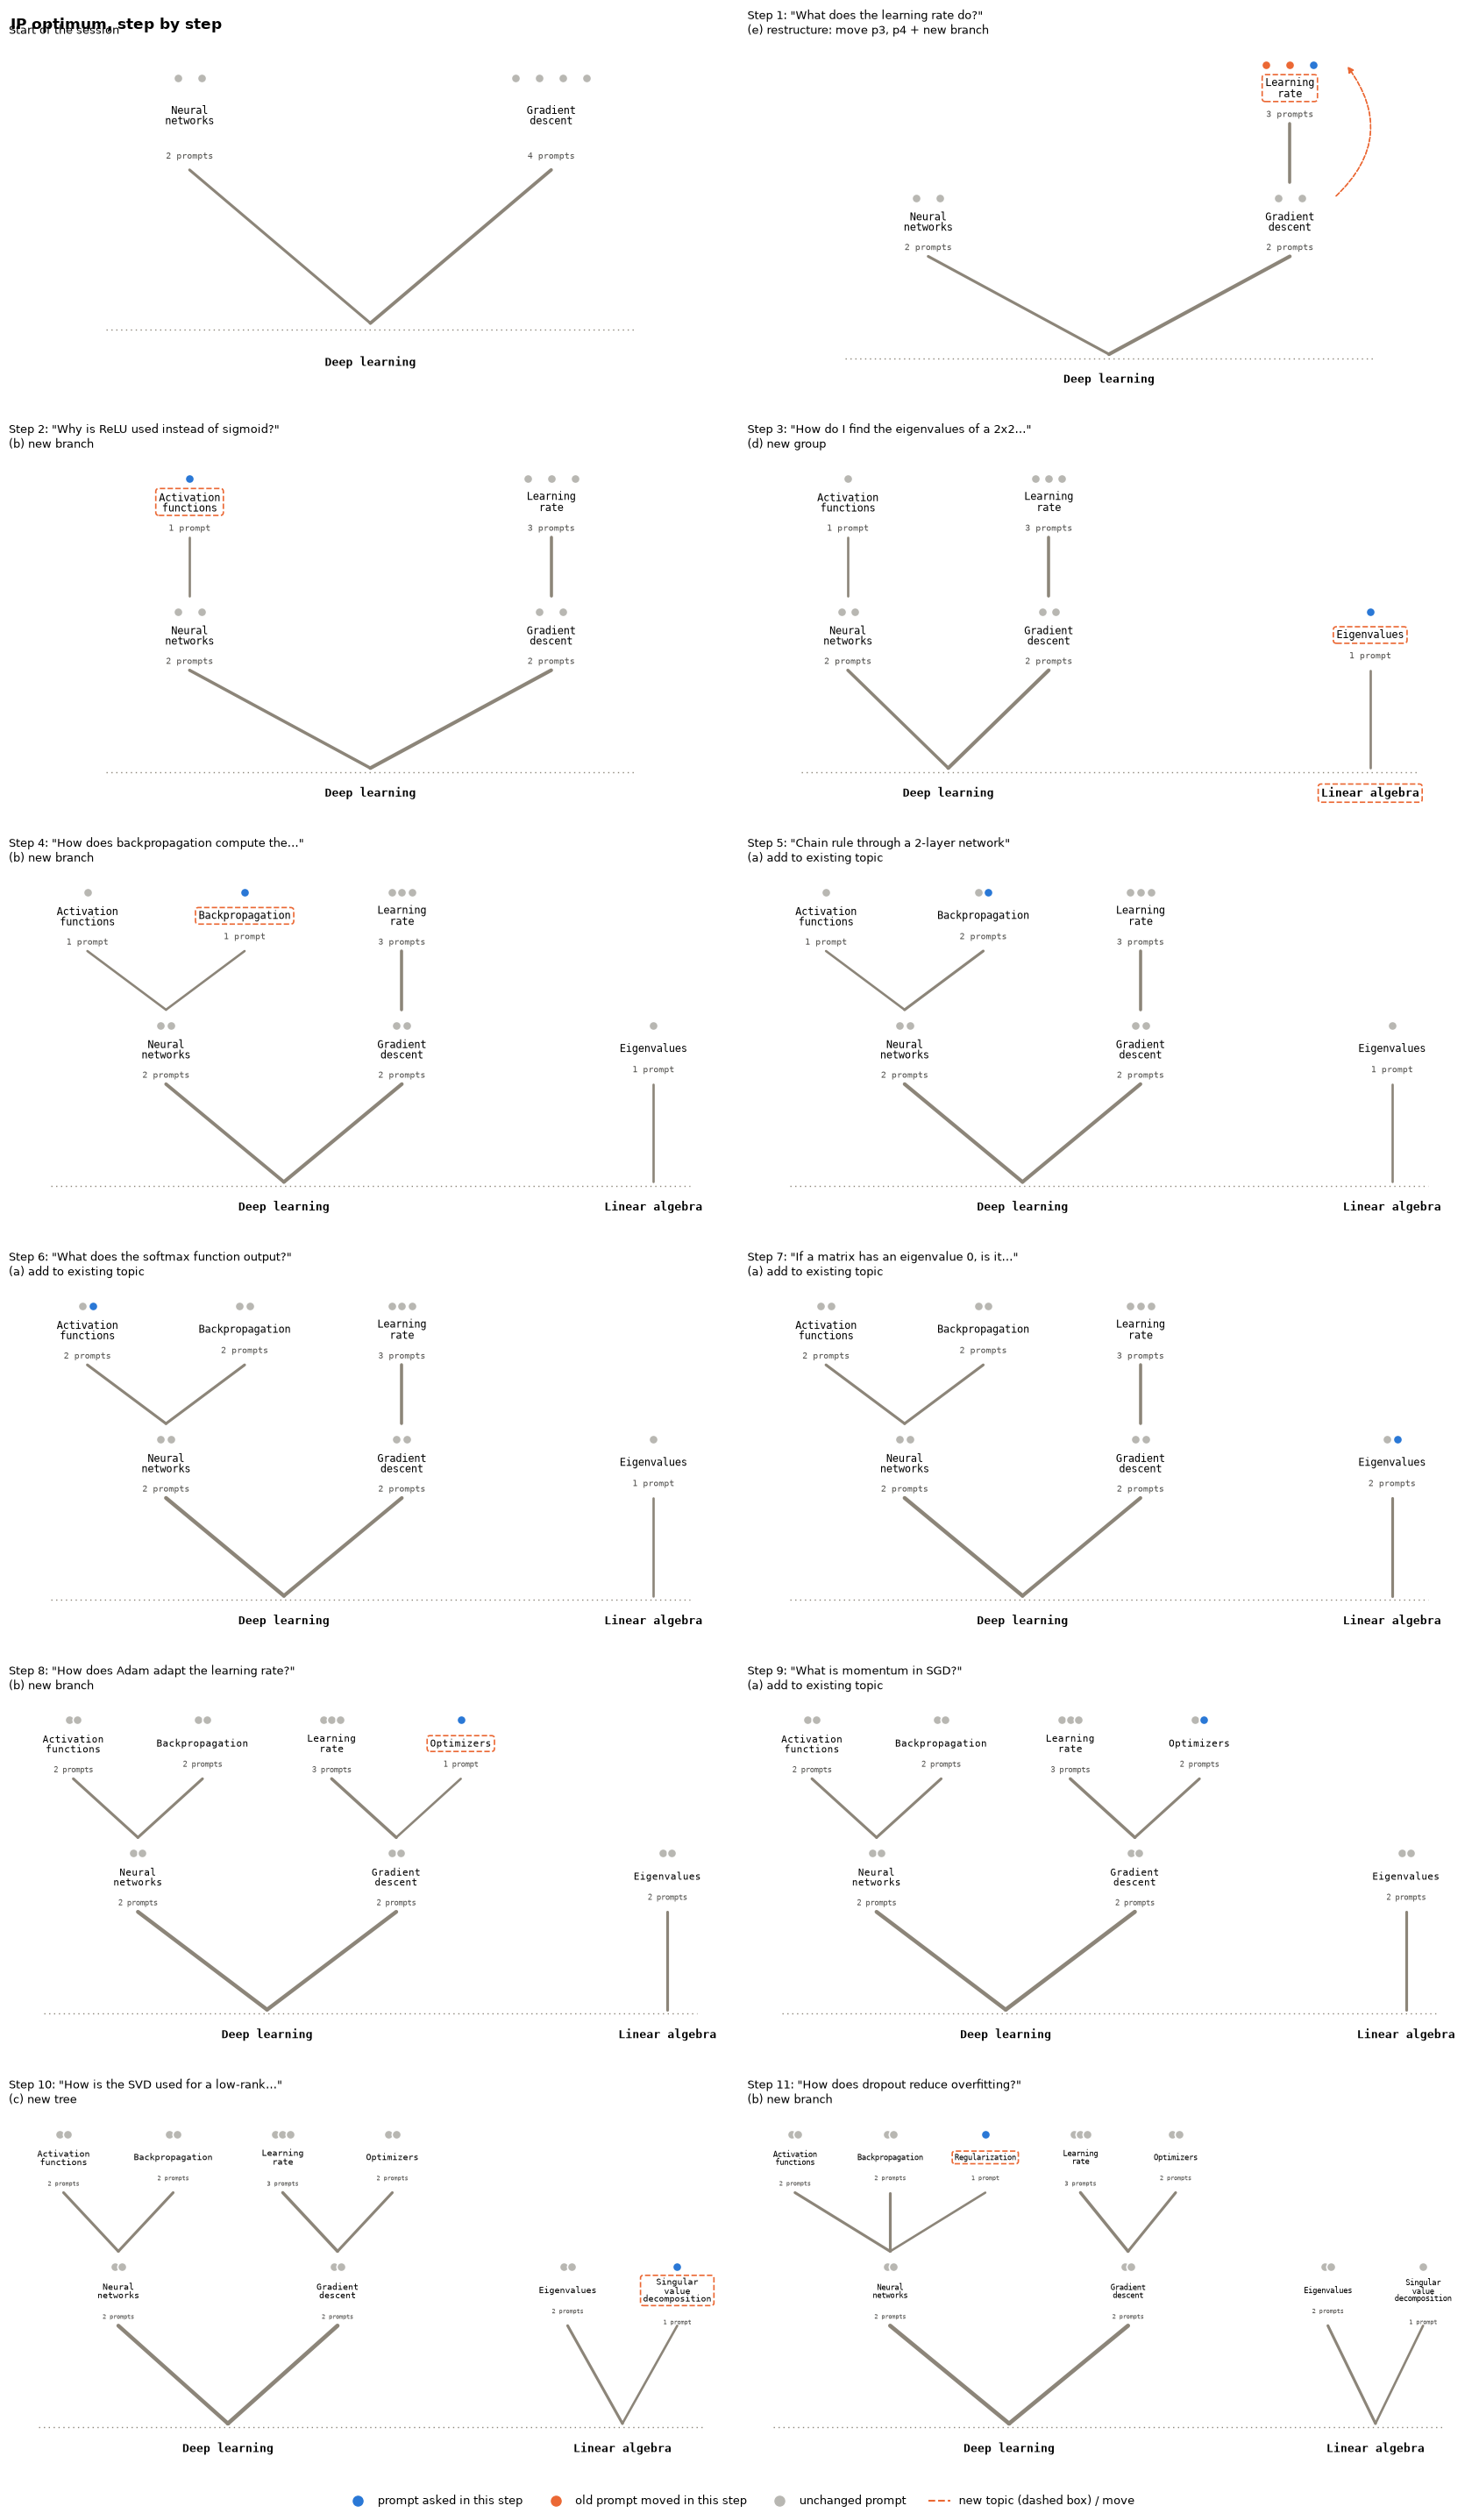

In [36]:
show_session(ip_history, "IP optimum, step by step")

## Visualization: one step in detail
The first restructure of the session (`K_SHOW`, Section 5b). Change `k` to look at any step.

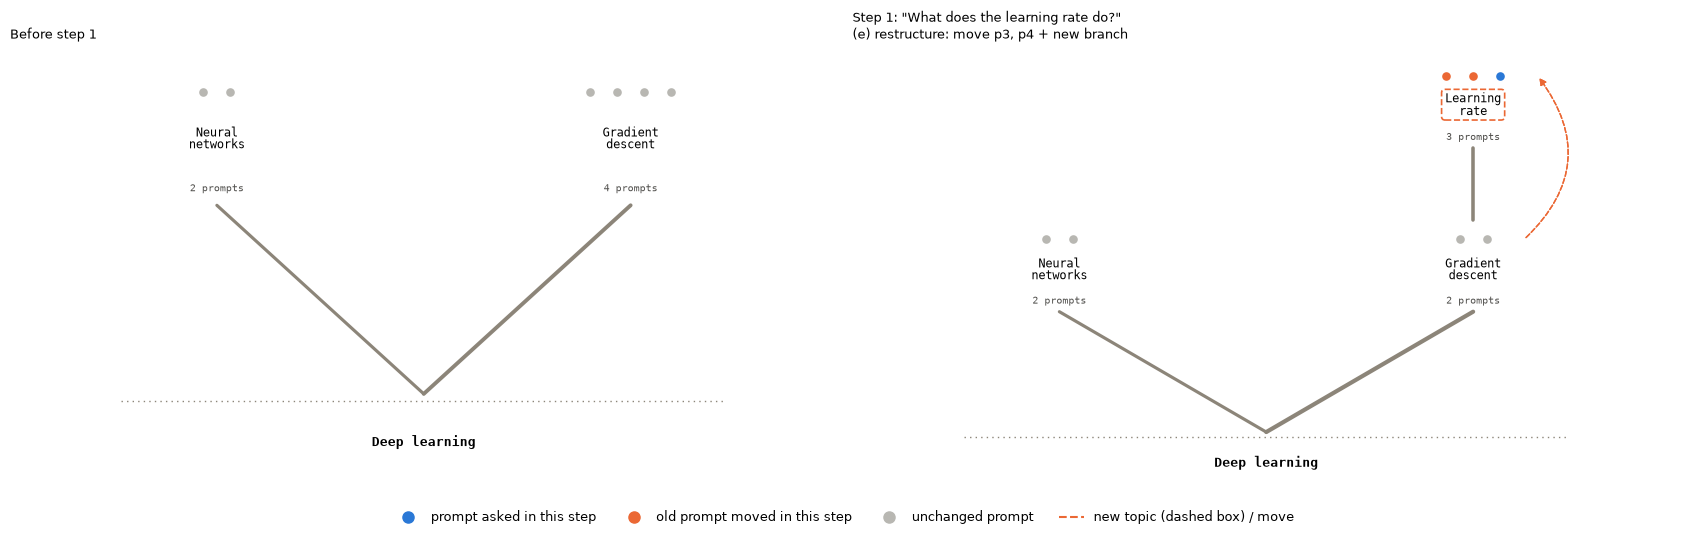

In [37]:
show_step(ip_history, k=K_SHOW)

## Animation: watch a step happen
The same step as an animation: moved prompts glide to their new topic, a new topic fades in. `animate_session(ip_history)` plays the whole session; with `gif="file.gif"` an animation is saved for slides.

In [38]:
animate_step(ip_history, k=K_SHOW)

## Why each decision?
For every step: the IP's decision, two simple alternatives (the new question into the **best existing topic**, i.e. the best-fitting one as (10) requires, or into the **best open proposal without moving anything**) with how many seconds **more** they cost, and the **runner-up**: the second-best decision of all, found by solving again with a "no-good cut" $\sum_p q_{p,a(p)} \le |P|-1$ that excludes the IP's assignment. The **margin** is its extra cost; a small margin means a small change of a parameter or of one score could flip the decision.

In [39]:
def explain_session(history):
    rows = []
    for h in history:
        state, step, n, params = h["before"], h["step"], h["step"]["id"], h["params"]
        keep = lambda c: {**state["assign"], n: c}                  # place n in c, nothing else moves
        cost = lambda c: evaluate_step(state, step, keep(c), params)["cost"]
        top = max(s(n, c) for c in state["topics"])               # file by meaning, constraint (10):
        best_old = min([c for c in state["topics"] if s(n, c) == top], key=cost)   # a best-fitting topic
        cands = [c for c in candidates_of(state, step) if s(n, c) >= top]
        best_new = min(cands, key=cost) if cands else None
        ip = h["parts"]["cost"]
        def versus(c):                                # how much more time than the IP's decision
            if c is None:
                return "- (no proposal)"
            if keep(c) == h["after"]["assign"]:
                return f"{ALL_LABELS[c]}  (= IP)"
            return f"{ALL_LABELS[c]}  (+{cost(c) - ip:.1f} s)"
        second, obj2 = solve_step(state, step, params, exclude=h["after"]["assign"])
        rows.append({
            "open proposals": ", ".join(ALL_LABELS[c] for c in cands) or "-",
            "IP decision": h["action"],
            "best existing topic": versus(best_old),
            "best proposal, no moves": versus(best_new),
            "runner-up (second best of all)": describe(state, step, second) if second else "-",
            "margin (s)": obj2 - ip if second else np.nan,
        })
    return pd.DataFrame(rows, index=pd.Index([h["k"] for h in history], name="step"))

print("Scores used:", SOURCE)
EXPLAIN = explain_session(ip_history)
EXPLAIN

Scores used: LLM, step by step (Claude Haiku 5.5 (claude-haiku-5-5), one fresh conversation per question that sees only that step's prompt); answers in llm_steps/


,open proposals,IP decision,best existing topic,"best proposal, no moves",runner-up (second best of all),margin (s)
step,,,,,,
1,Learning rate,"(e) restructure: move p3, p4 + new branch",Gradient descent (+3.3 s),Learning rate (+56.8 s),(a) n1 → Gradient descent,3.322
2,Activation functions,(b) new branch,Neural networks (+6.5 s),Activation functions (= IP),(a) n2 → Neural networks,6.500
3,Eigenvalues,(d) new group,Neural networks (+48.5 s),Eigenvalues (= IP),"(e) n3 → Eigenvalues, n2 → Neural networks",17.338
4,Backpropagation,(b) new branch,Neural networks (+4.7 s),Backpropagation (= IP),(a) n4 → Neural networks,4.745
5,-,(a) add to existing topic,Backpropagation (= IP),- (no proposal),"(e) n5 → Backpropagation, n2 → Neural networks",14.883
6,-,(a) add to existing topic,Activation functions (= IP),- (no proposal),"(e) n6 → Activation functions, p0 → Activation functions",33.063
7,-,(a) add to existing topic,Eigenvalues (= IP),- (no proposal),"(e) n7 → Eigenvalues, p0 → Activation functions",33.064
8,Optimizers,(b) new branch,Gradient descent (+3.0 s),Optimizers (= IP),(a) n8 → Gradient descent,2.990
9,-,(a) add to existing topic,Optimizers (= IP),- (no proposal),"(e) n9 → Gradient descent, n8 → Gradient descent",20.626


**How to read the table.** A new branch (b) pays off when the topic it splits from is long: the shorter list saves more reading than the extra level costs ($a + b\log_2 2 = 1.25$ s per lookup). A restructure (e) also moves old questions: it pays off when they would be misfiled once the new topic exists and the topic they leave is long, so that $H$ lookups save more than the one-time costs ($\mu_p$, $F$).

# 7. Human-made alternative designs
***
We run the same session with three best-effort rules a designer could write by hand. None of them ever moves an old prompt.

- **H0 – Chronological.** The status quo of chat sidebars: no topics by meaning, the new questions are listed in order, in blocks of three (*Chat 1: n1–n3*, …) in one group *Chat history*. Needs no LLM. Its labels are blocks of time, so in the user model the student cannot choose a branch by meaning: every lookup ends in scanning the history (misfiled term with probability 1).
- **H1 – Always add to the best existing topic.** Never grows the forest; a fixed folder structure.
- **H2 – Greedy best match.** Put the prompt in the best-scoring topic including the LLM's open proposals (a proposal only if it scores strictly higher), i.e. open a new topic, tree or group whenever the LLM proposes a better one. This is "picking the best option everywhere".

In [40]:
def h1_policy(state, step, params):
    best = max(state["topics"], key=lambda c: s(step["id"], c))
    return {**state["assign"], step["id"]: best}

def h2_policy(state, step, params):
    options = list(state["topics"]) + list(candidates_of(state, step))    # existing topics first: ties stay
    best = max(options, key=lambda c: s(step["id"], c))
    return {**state["assign"], step["id"]: best}

HISTORIES = {"H0: chronological": chronological(PARAMS),
             "H1: best existing topic": run_session(h1_policy),
             "H2: greedy best match": run_session(h2_policy),
             "IP optimum": ip_history}

outcome_table(HISTORIES)    # step by step: which outcome each design takes

,H0: chronological,H1: best existing topic,H2: greedy best match,IP optimum
step,,,,
1: What does the learning rate do?,d,a,b,e
2: Why is ReLU used instead of sigmoid?,a,a,b,b
3: How do I find the eigenvalues of a 2x2…,a,a,d,d
4: How does backpropagation compute the…,c,a,b,b
5: Chain rule through a 2-layer network,a,a,a,a
6: What does the softmax function output?,a,a,a,a
"7: If a matrix has an eigenvalue 0, is it still…",c,a,a,a
8: How does Adam adapt the learning rate?,a,a,b,b
9: What is momentum in SGD?,a,a,a,a


To compare whole sessions:
- *F1 topic / F1 tree*: agreement with the hand-made **ideal forest** (`IDEAL` in `session.py`, written before the LLM answers were collected, never shown to the LLM or the solver): pairwise F1 over "these two questions share a topic (tree)". It uses neither the LLM's scores nor our user model: an **independent check**.
- *lookup final / session*: mean time of one lookup in the final forest / averaged over the forests after every step (user model, Section 4a).
- *one-time*: costs of the changes during the session; *total*: $H$ lookups of every question in the final forest plus the one-time costs. The IP optimizes the same model, but only step by step, so it is not guaranteed to win on *total*.
- *mean fit*, *one-prompt topics*, *moves*; *missing scores*: pairs the LLM never rated because the answers were collected along the IP's path (they count as unrelated).

In [41]:
def pair_f1(assign, truth):
    # F1 of "these two questions are together" over all pairs, against truth {question: label}
    ps = sorted(assign)
    pred = {(a, b) for a, b in combinations(ps, 2) if assign[a] == assign[b]}
    true = {(a, b) for a, b in combinations(ps, 2) if truth[a] == truth[b]}
    return 1.0 if not pred and not true else 2 * len(pred & true) / (len(pred) + len(true))

def one_time_costs(history, params=PARAMS):
    # what the changes during the session cost the student once: new labels, moved questions, re-orientation (s)
    total = 0.0
    for h in history:
        moved, created, deleted, new_groups = changes(h["before"], h["after"])
        mu = move_costs(h["before"], params)
        total += (params["lam"] * len(created) + params["lam_G"] * len(new_groups)
                  + sum(mu[p] for p in moved) + params["F"] * bool(moved or deleted))
    return total

def session_metrics(history, params=PARAMS):
    final = history[-1]["after"]
    informative = history[0].get("informative", True)       # False for H0: its labels are blocks of time
    size = {c: sum(t == c for t in final["assign"].values()) for c in final["topics"]}
    rated = all(c in ALL_TOPICS for c in final["assign"].values())
    T_final = lookup_time(final, params, informative)
    return {
        "F1 topic": pair_f1(final["assign"], {p: IDEAL[p][2] for p in final["assign"]}),
        "F1 tree": pair_f1({p: tree_of(final, c) for p, c in final["assign"].items()},
                           {p: IDEAL[p][1] for p in final["assign"]}),
        "lookup final (s)": T_final,
        "lookup session (s)": np.mean([lookup_time(h["after"], params, informative) for h in history]),
        "one-time (s)": one_time_costs(history, params),
        "total (s)": params["H"] * T_final * len(final["assign"]) + one_time_costs(history, params),
        "mean fit": np.mean([s(p, c) for p, c in final["assign"].items()]) if rated else np.nan,
        "groups": len(final["groups"]),
        "topics": len(final["topics"]),
        "one-prompt topics": sum(v == 1 for v in size.values()),
        "moves": sum(len(changes(h["before"], h["after"])[0]) for h in history),
        "missing scores": sum(h["missing"] for h in history),
    }

COMPARE = pd.DataFrame({name: session_metrics(hist) for name, hist in HISTORIES.items()}).T
COMPARE

,F1 topic,F1 tree,lookup final (s),lookup session (s),one-time (s),total (s),mean fit,groups,topics,one-prompt topics,moves,missing scores
H0: chronological,0.296,0.391,13.747,11.216,5.000,2341.993,NaN,2.0,6.0,0.0,0.0,0.0
H1: best existing topic,0.263,0.611,9.455,7.169,0.000,1607.417,0.662,1.0,2.0,0.0,0.0,0.0
H2: greedy best match,0.571,0.806,6.029,5.971,8.000,1032.965,0.971,2.0,9.0,3.0,0.0,0.0
IP optimum,0.842,0.806,5.010,4.930,26.178,877.899,1.000,2.0,9.0,2.0,2.0,0.0


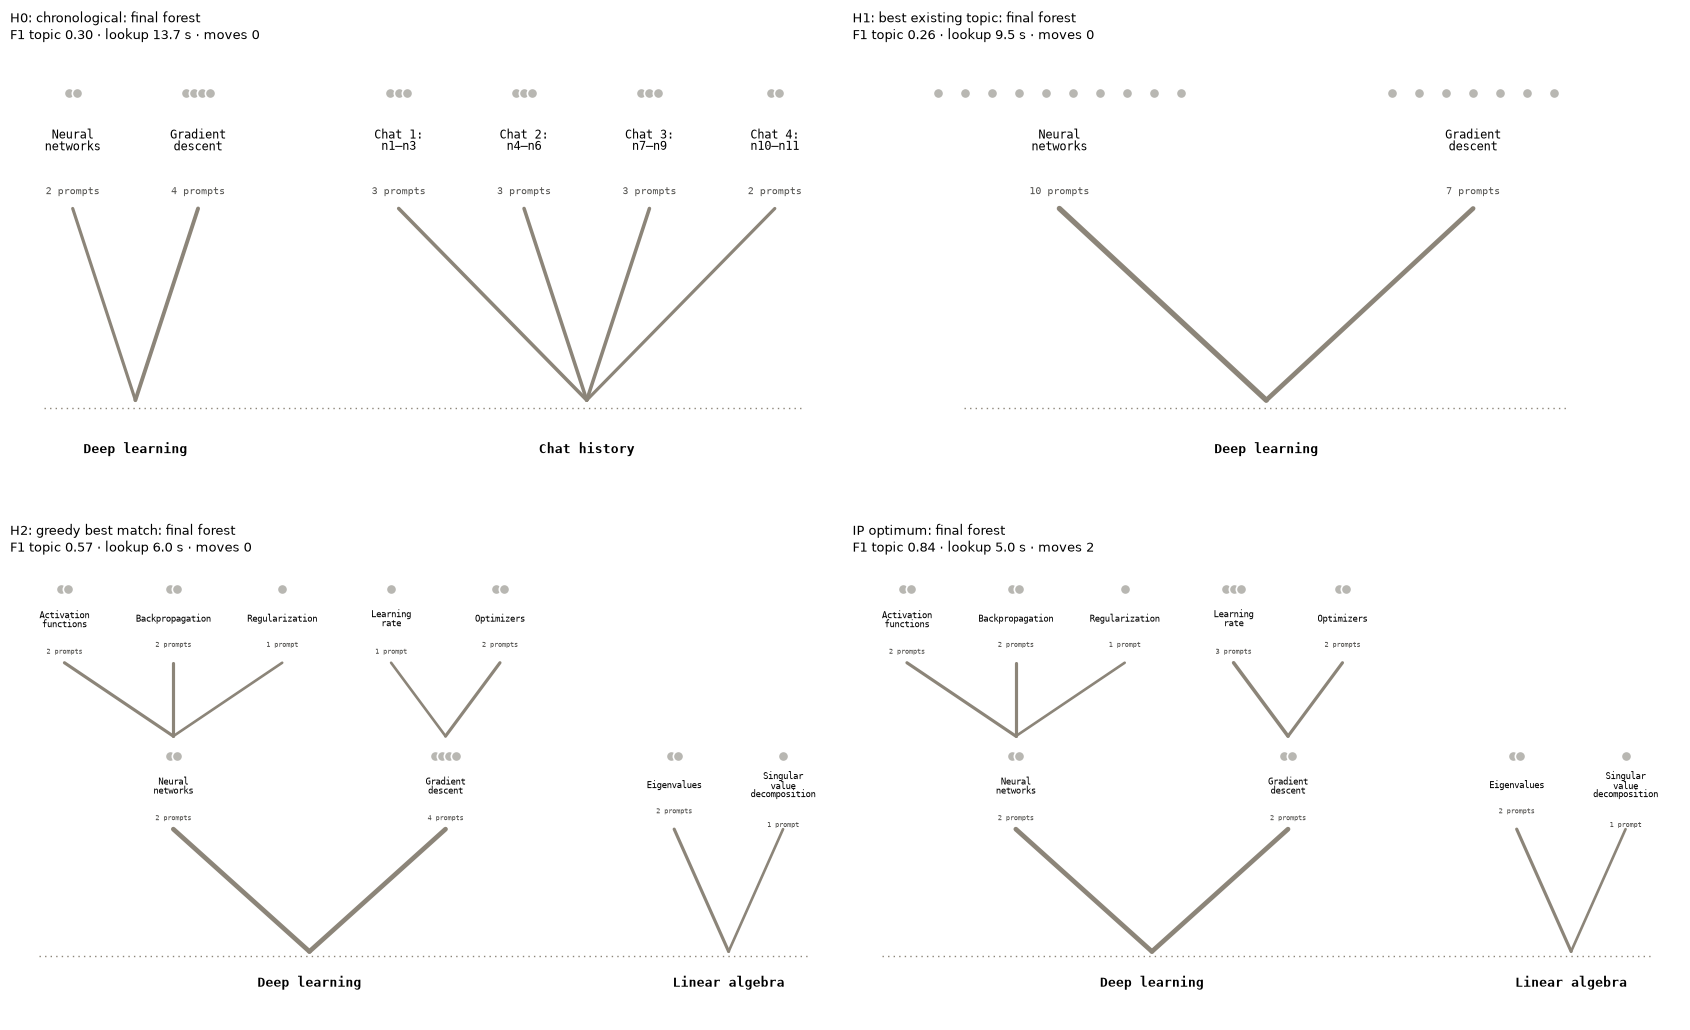

In [42]:
show_final_trees(HISTORIES, metrics=lambda h: (f"F1 topic {session_metrics(h)['F1 topic']:.2f} · "
                                               f"lookup {session_metrics(h)['lookup final (s)']:.1f} s · "
                                               f"moves {session_metrics(h)['moves']}"))

**Discussion** (numbers from the run above, $H = 10$).
- **H0, chronological**: time blocks carry no meaning, so every lookup ends in the history: 13.7 s per lookup, F1 topic 0.30.
- **H1, best existing topic**: two topics with 10 and 7 questions, linear algebra filed under *Neural networks*: 9.5 s per lookup, F1 topic 0.26.
- **H2, greedy best match**: opens every proposed topic for the question that triggered it and never moves: 6.0 s per lookup. At step 1 *Learning rate* receives only n1, while p3 and p4 (rated 5 for it, 4 for *Gradient descent*) stay misfiled in a long *Gradient descent* (F1 topic 0.57).
- **The IP** ends with the same topics as H2 and differs in one decision: at step 1 it **also moves p3 and p4** into *Learning rate*, i.e. it splits the overloaded topic (step 1 costs 357.8 s instead of 414.6 s for H2's choice). Over the session its one-time costs are 26 s instead of 8 s, and every lookup is about 1 s faster: 5.0 s (−17 %), 878 s instead of 1033 s in total (−15 %). It also agrees best with the ideal forest (F1 topic 0.84), which it never saw.
- **Close calls.** A topic for a single new question (steps 2, 4, 8, 11) wins by only 2.5–6.5 s against filing the question in the parent: the shorter list saves a little more reading than the extra level costs. With other parameters the IP waits instead and creates the topic when the second question of the theme arrives, moving the first one in (Section 8).
- **New subjects** get their own group or tree at once (steps 3 and 10): the best existing topic would cost 48.5 s and 58.9 s more.

The IP differs from "best option everywhere" exactly where a rule that only looks at the new question cannot help: when a new topic leaves old questions misfiled in a long list. Whether learners prefer this forest is tested in Milestone 4.

# 8. What-if analysis
***
The whole session re-run with one parameter changed: the outcomes of the eleven steps (a–e), and the IP's total time next to that of the greedy rule H2. The runs reuse the LLM answers collected along the IP's default path (column *missing scores*).

**How often will the student look questions up again?** $H$ weighs lasting lookup time against one-time costs.

In [43]:
def sweep(name, values):
    rows = []
    for v in values:
        params = {**PARAMS, name: v}
        hist = run_session(params=params)
        m, h2 = session_metrics(hist, params), session_metrics(run_session(h2_policy, params), params)
        rows.append({name: v, "outcomes (steps 1-11)": " ".join(code_of(h["action"]) for h in hist),
                     **{k: m[k] for k in ("F1 topic", "topics", "moves", "lookup final (s)", "one-time (s)", "total (s)")},
                     "total H2 (s)": h2["total (s)"], "missing scores": m["missing scores"]})
    return pd.DataFrame(rows).set_index(name)

sweep("H", [1, 2, 3, 5, 10, 20, 40])

,outcomes (steps 1-11),F1 topic,topics,moves,lookup final (s),one-time (s),total (s),total H2 (s),missing scores
H,,,,,,,,,
1,a a d b a a a b a c b,0.690,7,0,5.441,6.000,98.497,110.497,0
2,a b d b a a a b a c a,0.593,7,0,5.137,6.000,180.669,212.993,0
3,a b d b a a a b a c b,0.640,8,0,5.117,7.000,267.950,315.490,0
5,a b d b a a a b a c b,0.640,8,0,5.117,7.000,441.917,520.483,0
10,e b d b a a a b a c b,0.842,9,2,5.010,26.178,877.899,1032.965,0
20,e b d b a a a b a c b,0.842,9,2,5.010,26.178,1729.619,2057.931,0
40,e b d b a a a b a c b,0.842,9,2,5.010,26.178,3433.060,4107.862,0


**How much does a restructure disturb?** $F$ is the fixed re-orientation cost of any restructure.

In [44]:
sweep("F", [0, 2.5, 5, 10, 20, 40])

,outcomes (steps 1-11),F1 topic,topics,moves,lookup final (s),one-time (s),total (s),total H2 (s),missing scores
F,,,,,,,,,
0.0,e b d b a a a b a c b,0.842,9,2,5.010,21.178,872.899,1032.965,0
2.5,e b d b a a a b a c b,0.842,9,2,5.010,23.678,875.399,1032.965,0
5.0,e b d b a a a b a c b,0.842,9,2,5.010,26.178,877.899,1032.965,0
10.0,a b d b a a a b a c b,0.640,8,0,5.117,7.000,876.833,1032.965,0
20.0,a b d b a a a b a c b,0.640,8,0,5.117,7.000,876.833,1032.965,0
40.0,a b d b a a a b a c b,0.640,8,0,5.117,7.000,876.833,1032.965,0


**How slow is reading?** $R$ is the time to read one question while scanning a topic; it sets how expensive long topics are.

In [45]:
sweep("R", [0.5, 0.75, 1.0, 1.5, 2.0])

,outcomes (steps 1-11),F1 topic,topics,moves,lookup final (s),one-time (s),total (s),total H2 (s),missing scores
R,,,,,,,,,
0.50,a a d b a a a b a c e,0.593,7,2,4.137,20.363,723.706,802.965,0
0.75,a b d a e a a b a c a,0.593,7,1,4.637,15.925,804.268,917.965,0
1.00,e b d b a a a b a c b,0.842,9,2,5.010,26.178,877.899,1032.965,0
1.50,e b d b a a a b a c b,0.842,9,2,5.775,30.178,1011.899,1262.965,0
2.00,e b d b a a a b a c b,0.842,9,2,6.540,34.178,1145.899,1492.965,0


**How expensive is a level?** $a$ is the time to open one level of the tree; it sets how expensive deep trees are.

In [46]:
sweep("a", [0.3, 0.6, 1.1, 2.0, 3.0])

,outcomes (steps 1-11),F1 topic,topics,moves,lookup final (s),one-time (s),total (s),total H2 (s),missing scores
a,,,,,,,,,
0.3,e b d b a a a b a c b,0.842,9,2,2.940,22.978,522.699,696.965,0
0.6,e b d b a a a b a c b,0.842,9,2,3.716,24.178,655.899,822.965,0
1.1,e b d b a a a b a c b,0.842,9,2,5.010,26.178,877.899,1032.965,0
2.0,a a d b a e a b a c a,0.593,7,1,7.255,18.478,1251.821,1410.965,0
3.0,a a d a e a a b a c e,0.593,7,3,9.608,47.438,1680.781,1830.965,0


# 9. Critical examination: limitations
***
**What the what-if analysis shows.** The split of *Gradient descent* pays off only if questions are looked up often enough ($H \ge 10$) and restructures are cheap enough ($F \le 5$ s); otherwise n1 is filed in *Gradient descent* and the old questions stay. The topics for single questions are the most sensitive decisions: with few lookups ($H \le 2$), cheaper reading ($R \le 0.75$ s) or expensive levels ($a \ge 2$ s) the IP files the first question of a theme in the parent. When the second one arrives, it either creates the topic and moves the first one in (backpropagation at $R = 0.75$ s, activation functions at $a = 2$ s) or, with very few lookups ($H = 1$), keeps both in the parent. In every run the IP's total time is below that of the greedy rule H2.

**Inputs from the LLM.** One run of one model (Claude Haiku 5.5), not repeated and not compared with human ratings; the CLI has no temperature setting, so reproducibility relies on the saved answers. The baselines and what-if runs reuse answers collected along the IP's path (no unrated pair was needed, but on other paths the LLM might have proposed other topics). The LLM's topics and parents are taken as they are. Its scores decide a lot: p0 ("What does an activation function do?") stays in *Neural networks* because the LLM rates it 5 there and 5 for *Activation functions*, so it is not misfiled. Coarse scores make ties common; a tiny tie-breaker (0.001 s per later question) moves the more recent question.

**The user model.** $a$, $b$, $R$ are literature values, not fitted to our tree view; $H$ and $F$ are assumptions. Labels are assumed to be recognised perfectly; a score of 4 counts as "found here" when no better topic exists, and a misfiled question costs a scan of the whole history wherever it is. Visual clutter is not modelled. Each step is optimized on its own (myopic); topics are never moved, renamed or merged; at most one new topic per step.

**The evaluation.** One short scripted session written by us. Its questions were chosen so that every outcome occurs, and we reworded two starting questions after a first run, in which the LLM rated them 5 for *Gradient descent* as well as for *Learning rate*. The ideal forest is one reasonable grouping among several (10 "together" pairs). Lookup time comes from the model the IP optimizes; only F1 is independent. Whether students really find their questions faster is tested in Milestone 4, whose logged lookup times could also be used to fit $a$, $b$, $R$ and $H$.

**References**
- Anthropic (2026). Claude Haiku 5.5 (`claude-haiku-5-5`), accessed through the Claude Code CLI on 27 Nov 2026.
- Card, S. K., Moran, T. P., & Newell, A. (1980). The keystroke-level model for user performance time with interactive systems. *Communications of the ACM*, 23(7), 396–410.
- Card, S. K., Moran, T. P., & Newell, A. (1983). *The Psychology of Human-Computer Interaction*. Lawrence Erlbaum.
- Cockburn, A., Gutwin, C., & Greenberg, S. (2007). A predictive model of menu performance. *Proc. CHI 2007*, 627–636.
- Hick, W. E. (1952). On the rate of gain of information. *Quarterly Journal of Experimental Psychology*, 4(1), 11–26.
- Hyman, R. (1953). Stimulus information as a determinant of reaction time. *Journal of Experimental Psychology*, 45(3), 188–196.
- Kiger, J. I. (1984). The depth/breadth trade-off in the design of menu-driven user interfaces. *International Journal of Man-Machine Studies*, 20(2), 201–213.
- Miller, D. P. (1981). The depth/breadth tradeoff in hierarchical computer menus. *Proc. Human Factors Society Annual Meeting*, 25(1), 296–300.

# 10. Export for the prototype
***
The forest after every step of the IP run, as JSON, so the prototype can show the same sequence in the Milestone 4 study.

In [47]:
export_sequence(ip_history, PARAMS)

saved export/ip_forest_sequence.json with 11 steps


# Appendix: the LLM prompt (propose, then judge)
***
The step prompt that was sent for the step after the first new group (or step 6): fixed parts plus the current forest, the open proposals, the missing scores and the new question. All prompts actually sent are stored in `llm_steps/<id>_prompt.txt`, next to the answers.

In [48]:
K_PROMPT = next((h["k"] + 1 for h in ip_history if code_of(h["action"]) == "d" and h["k"] < len(ip_history)), 6)
n = SESSION[K_PROMPT - 1]["id"]
print(f"=== step {K_PROMPT} ({n}): llm_steps/{n}_prompt.txt ===\n")
print(open(f"llm_steps/{n}_prompt.txt").read())

=== step 4 (n4): llm_steps/n4_prompt.txt ===

You help a study tool that sorts the questions a student asks an AI tutor into a knowledge forest: groups (one per subject) hold trees of topics, and every question sits in one topic.
A new question arrived. Do two tasks.

TASK 1 - PROPOSE
Decide whether the forest needs a new topic for the NEW question.
- Propose a new topic only if the question would get 5 for it and at most 4 for every topic listed
  below (including the open proposals). Otherwise propose nothing (null).
- At most one new topic. Name it in 1-3 words, as a student would label a folder.
- Choose its parent:
  * the most specific fitting topic id from "Topics in the forest" (a new branch), or
  * a group id, to start a new tree in that subject, or
  * "NEW_GROUP: <subject name>" if the question belongs to a subject that has no group yet.
  An open proposal cannot be a parent.
- Never propose a topic that already exists or was already proposed (same meaning, other words).
- 